# Phase 9 Validation & Analysis

Authoritative validation notebook for `data/processed/scores/complexity_index_v2.csv` (Phase 9.5 rubric: 30/70 technical/practical split — see `docs/superpowers/specs/2026-07-14-phase9.5-rubric-revision-design.md`) (self-contained — re-derives team-size correlation and manual outlier review fresh rather than citing `notebooks/score_design.ipynb`). Covers score distribution, technical-vs-practical relationship, complexity by batch/status/industry, a full correlation heatmap, team-size correlation, targeted validation questions, manual outlier review, success correlation (topCompany badge and Acquired/Public status), a confound-controlled logistic regression of success on complexity/team size/batch vintage/founder pedigree, and findings, per `docs/superpowers/specs/2026-07-13-phase9-validation-analysis-design.md`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

scores_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "scores" / "complexity_index_v2.csv")
bucket_score_cols = [c for c in scores_df.columns if c.endswith("_score") and c not in ("technical_score", "practical_score", "complexity_score")]
features_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "features" / "complexity_features.parquet")
companies_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "companies_enriched.csv")
industries_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "industries_enriched.csv")
badges_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "badges_enriched.csv")
founders_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "founders_enriched.csv")
schools_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "schools_enriched.csv")

merged = scores_df.merge(companies_df[["id", "teamSize"]], on="id", how="left")
merged["log_team_size"] = np.log1p(merged["teamSize"])

feature_cols = [c for c in features_df.columns if c not in ("id", "slug", "name", "batch", "status") and c not in scores_df.columns]
merged = merged.merge(features_df[["id"] + feature_cols], on="id", how="left")

top_company_ids = set(badges_df.loc[badges_df["badge"] == "topCompany", "id"])
merged["is_top_company"] = merged["id"].isin(top_company_ids).astype(float)
merged["is_acquired_or_public"] = merged["status"].isin(["Acquired", "Public"]).astype(float)

industry_merged = scores_df.merge(industries_df, on="id", how="left")

merged.shape, industry_merged.shape

((4844, 26), (8857, 16))

## 1. Score Distribution

Objectives doc target: standard deviation ≥ 15 points (avoid clustering).

array([[<Axes: title={'center': 'complexity_score'}>,
        <Axes: title={'center': 'technical_score'}>,
        <Axes: title={'center': 'practical_score'}>]], dtype=object)

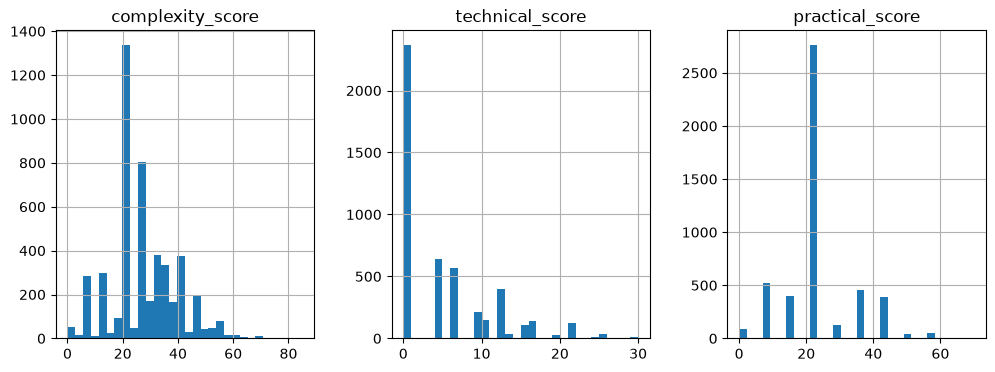

In [2]:
merged[["complexity_score", "technical_score", "practical_score"]].hist(bins=30, figsize=(12, 4), layout=(1, 3))

In [3]:
std = merged["complexity_score"].std()
print(f"complexity_score std: {std:.2f} (target: >= 15)")
merged["complexity_score"].describe()

complexity_score std: 11.95 (target: >= 15)


count    4844.000000
mean       27.362923
std        11.950224
min         0.000000
25%        21.000000
50%        25.500000
75%        35.000000
max        85.000000
Name: complexity_score, dtype: float64

## 2. Technical vs Practical

Checks whether the two 0-50 sub-scores move together or measure independent dimensions of complexity, as the rubric intends.

Correlation between technical_score and practical_score: -0.051


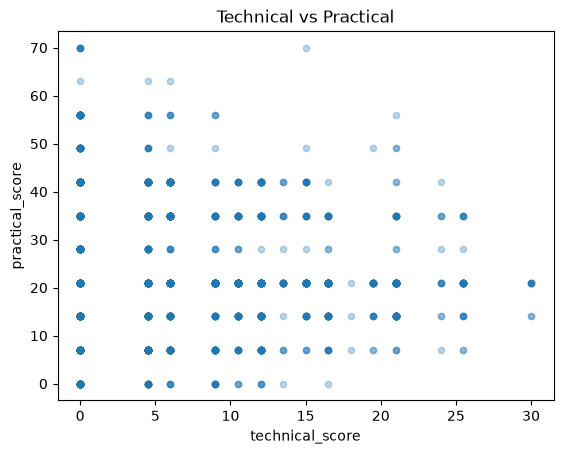

In [4]:
merged.plot(kind="scatter", x="technical_score", y="practical_score", alpha=0.3, title="Technical vs Practical")
tp_corr = merged["technical_score"].corr(merged["practical_score"])
print(f"Correlation between technical_score and practical_score: {tp_corr:.3f}")

## 3. Complexity by Batch

Mean/median `complexity_score` per batch, ordered chronologically (Winter before Summer within the same year), not alphabetically.

,batch,mean,median,count
0,S05,19.187500,21.00,8
20,W06,19.285714,21.00,7
1,S06,13.590909,11.50,11
21,W07,14.153846,14.00,13
2,S07,15.000000,11.50,19
22,W08,18.285714,21.00,21
3,S08,14.795455,9.25,22
23,W09,14.968750,12.75,16
4,S09,19.250000,21.00,26
24,W10,17.574074,21.00,27


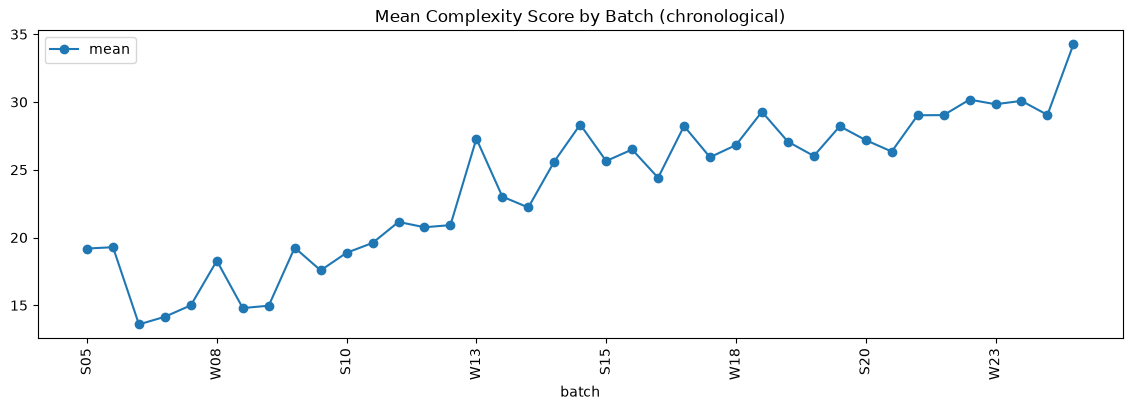

In [5]:
def batch_sort_key(batch: str) -> tuple:
    year = int(batch[1:])
    season_order = 0 if batch[0] == "W" else 1
    return (year, season_order)

batch_summary = merged.groupby("batch")["complexity_score"].agg(["mean", "median", "count"]).reset_index()
batch_summary["sort_key"] = batch_summary["batch"].apply(batch_sort_key)
batch_summary = batch_summary.sort_values("sort_key").drop(columns="sort_key")

batch_summary.plot(
    x="batch", y="mean", kind="line", marker="o", figsize=(14, 4),
    title="Mean Complexity Score by Batch (chronological)", rot=90,
)
batch_summary

## 4. Complexity by Status

Validation question: are Public companies more complex than average?

In [6]:
status_summary = merged.groupby("status")["complexity_score"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
overall_mean = merged["complexity_score"].mean()
print(f"Overall mean complexity_score: {overall_mean:.2f}")
status_summary

Overall mean complexity_score: 27.36


,mean,median,count
status,,,
Active,29.120169,27.0,3441
Public,28.973684,29.0,19
Acquired,23.860104,21.0,579
Inactive,22.332919,21.0,805


## 5. Complexity by Industry

Each company contributes its `complexity_score` to every industry it's tagged with (explode, not a single primary industry). Filtered to industries with >= 20 tagged companies to avoid noisy single-company averages.

,mean,count
industry,,
Legal,49.439394,33
Finance and Accounting,46.576577,111
Supply Chain and Logistics,42.745614,114
Drug Discovery and Delivery,40.500000,42
Industrial Bio,39.794118,34
Medical Devices,39.488095,42
Therapeutics,36.254098,61
Diagnostics,35.648148,54
Healthcare,33.448217,589


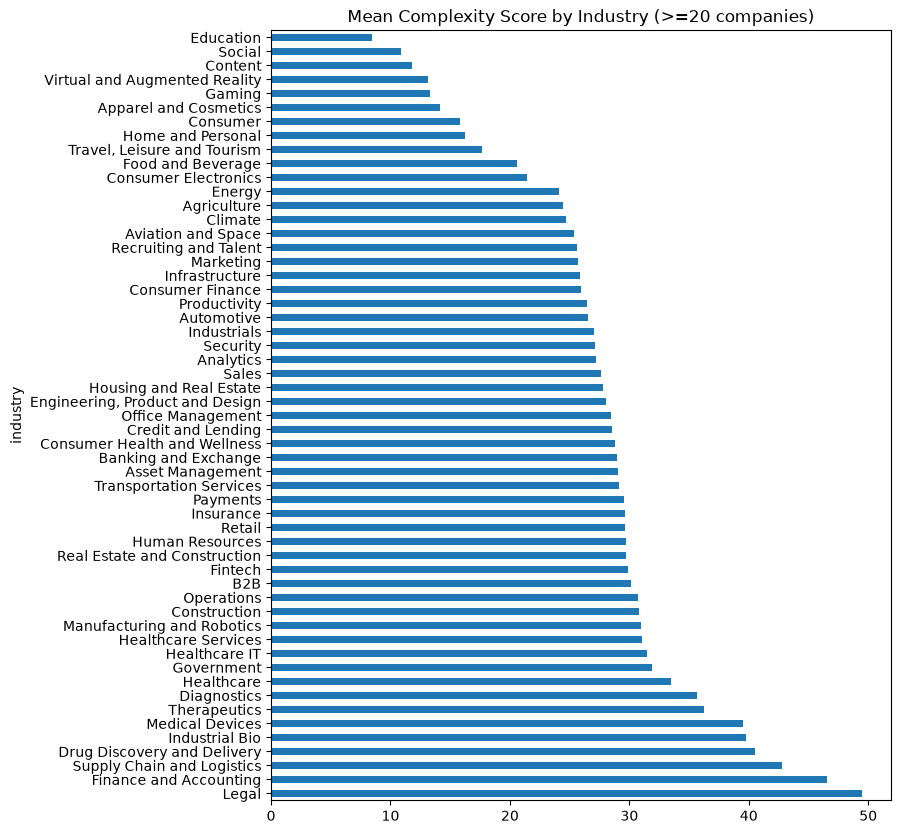

In [7]:
industry_summary = (
    industry_merged.groupby("industry")["complexity_score"]
    .agg(["mean", "count"])
    .query("count >= 20")
    .sort_values("mean", ascending=False)
)
industry_summary.plot(
    kind="barh", y="mean", figsize=(8, 10),
    title="Mean Complexity Score by Industry (>=20 companies)", legend=False,
)
industry_summary

## 6. Correlation Heatmap

Correlation matrix across all 8 raw features (`complexity_features.parquet`), the rubric's bucket scores, and the 3 top-level scores.

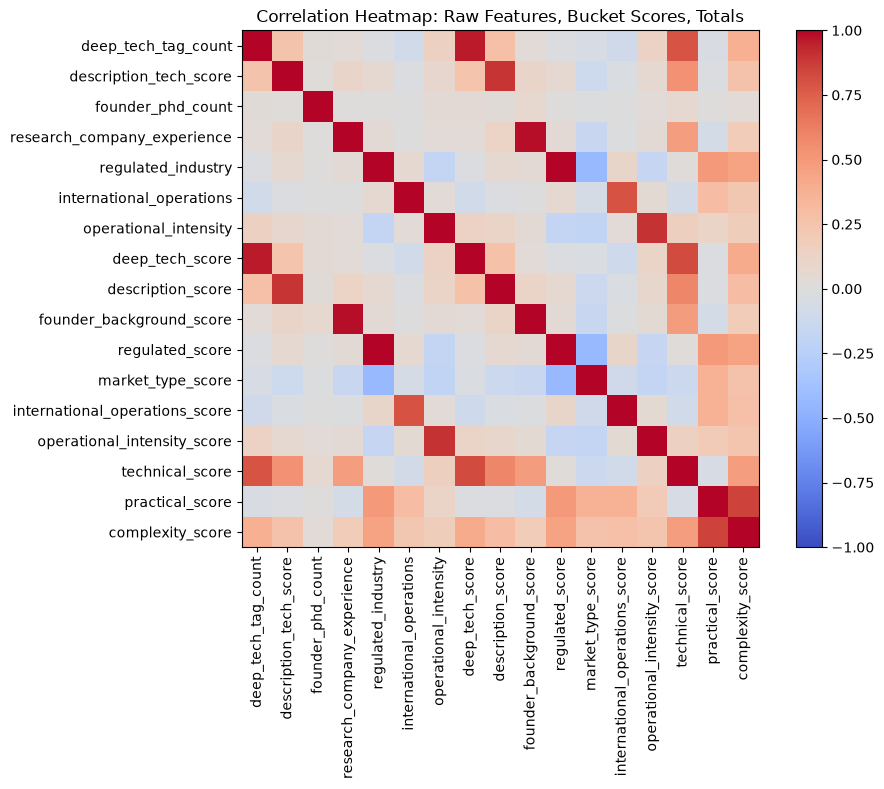

In [8]:
import matplotlib.pyplot as plt

corr_cols = feature_cols + bucket_score_cols + [
    "technical_score", "practical_score", "complexity_score",
]
corr_matrix = merged[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation Heatmap: Raw Features, Bucket Scores, Totals")
fig.tight_layout()

## 7. Team-Size Correlation

Objectives doc target: `r > 0.2` with team size. `teamSize` is heavily right-skewed (median 7, max 8,600), so it's log1p-transformed before correlating. Re-derived fresh here (not copied from `notebooks/score_design.ipynb`) so this notebook is self-contained.

In [9]:
team_size_valid = merged.dropna(subset=["teamSize"])
pearson_r = team_size_valid["complexity_score"].corr(team_size_valid["log_team_size"], method="pearson")
spearman_r = team_size_valid["complexity_score"].corr(team_size_valid["log_team_size"], method="spearman")
print(f"Pearson r (complexity_score vs log1p(teamSize)): {pearson_r:.3f}")
print(f"Spearman r: {spearman_r:.3f}")
print("Target from objectives doc: r > 0.2")
print(f"n = {len(team_size_valid)} companies with known teamSize")

Pearson r (complexity_score vs log1p(teamSize)): 0.103
Spearman r: 0.102
Target from objectives doc: r > 0.2
n = 4766 companies with known teamSize


## 8. Validation Questions

Do Healthcare-tagged companies skew high on `technical_score`? Do Fintech-tagged companies skew high on `practical_score`/`regulated_score`? (No distinct "Biotech" industry tag exists in this dataset — `Healthcare` is the closest proxy for deep-tech/hard-science regulation.)

In [10]:
def industry_group_mean(industry_name: str, score_col: str) -> tuple:
    tagged = industry_merged[industry_merged["industry"] == industry_name][score_col]
    overall = industry_merged[score_col].mean()
    return tagged.mean(), overall, len(tagged)

for industry_name, score_col in [
    ("Healthcare", "technical_score"),
    ("Fintech", "practical_score"),
    ("Fintech", "regulated_score"),
]:
    group_mean, overall_mean_val, n = industry_group_mean(industry_name, score_col)
    print(f"{industry_name} mean {score_col}: {group_mean:.2f} (n={n}) vs overall mean: {overall_mean_val:.2f}")

Healthcare mean technical_score: 9.20 (n=589) vs overall mean: 4.90
Fintech mean practical_score: 27.94 (n=566) vs overall mean: 22.53
Fintech mean regulated_score: 21.00 (n=566) vs overall mean: 6.68


## 9. Manual Review of Outliers

Objectives doc target: top/bottom 25 companies should make sense on manual inspection. Re-derived fresh here (not copied from `notebooks/score_design.ipynb`).

In [11]:
bucket_cols = ["slug", "name", "batch", "status"] + bucket_score_cols + [
    "technical_score", "practical_score", "complexity_score",
]
top_25 = merged.sort_values("complexity_score", ascending=False)[bucket_cols].head(25)
top_25

,slug,name,batch,status,deep_tech_score,description_score,founder_background_score,regulated_score,market_type_score,international_operations_score,operational_intensity_score,technical_score,practical_score,complexity_score
2078,be-go,BeGo,W20,Active,6.0,9.0,0.0,21.0,21.0,14.0,14.0,15.0,70.0,85.0
3422,redbrick-ai,RedBrick AI,W22,Active,12.0,9.0,0.0,21.0,21.0,14.0,0.0,21.0,56.0,77.0
1182,bulk-mro-industrial-supply,Bulk MRO Industrial Supply,W17,Active,0.0,0.0,0.0,21.0,21.0,14.0,14.0,0.0,70.0,70.0
3009,trackchain,TrackChain,S21,Active,0.0,0.0,0.0,21.0,21.0,14.0,14.0,0.0,70.0,70.0
2230,valienta,Valienta,W20,Inactive,0.0,0.0,0.0,21.0,21.0,14.0,14.0,0.0,70.0,70.0
703,taxa-biotechnologies,TAXA Biotechnologies,S14,Inactive,12.0,4.5,4.5,21.0,0.0,14.0,14.0,21.0,49.0,70.0
3336,dimorder,DimOrder,W22,Active,0.0,0.0,0.0,21.0,21.0,14.0,14.0,0.0,70.0,70.0
3831,pivo-technology-inc,Pivo Technology Inc,S22,Inactive,0.0,0.0,0.0,21.0,21.0,14.0,14.0,0.0,70.0,70.0
1450,nuvocargo,Nuvocargo,W18,Active,0.0,0.0,0.0,21.0,21.0,14.0,14.0,0.0,70.0,70.0
1408,vena-medical,Vena Medical,W18,Active,12.0,0.0,9.0,21.0,0.0,14.0,14.0,21.0,49.0,70.0


In [12]:
bottom_25 = merged.sort_values("complexity_score", ascending=True)[bucket_cols].head(25)
bottom_25

,slug,name,batch,status,deep_tech_score,description_score,founder_background_score,regulated_score,market_type_score,international_operations_score,operational_intensity_score,technical_score,practical_score,complexity_score
2110,stayqrious,StayQrious,W20,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3084,algouniversity,AlgoUniversity,S21,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1360,py,Py,S17,Acquired,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1354,mystery-org,Mystery.org,S17,Acquired,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
583,codenow,CodeNow,W14,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1459,nexgent,NEXGENT,W18,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3067,studystream,StudyStream,S21,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
584,codecombat,CodeCombat,W14,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1315,pathrise,Pathrise,S17,Active,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1503,glimpse-k12,Glimpse K12,W18,Acquired,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 10. Success Correlation

Does complexity predict startup success? Two outcome proxies, per `documentation/dataset/dataset_overview.md`:
- **Strict**: the `topCompany` badge (1.9% of companies) -- YC's own top-performer flag.
- **Broad**: `status` in `{Acquired, Public}` (12.4%) -- reached a liquidity/scale outcome.

Both are 0/1 flags, so `.corr()` against `complexity_score` is exactly the point-biserial correlation. Neither definition was part of the original rubric design or its calibration targets -- this is a fresh validation question, not a target the scoring was tuned against.

In [13]:
for flag_col, label in [("is_top_company", "topCompany (strict)"), ("is_acquired_or_public", "Acquired/Public (broad)")]:
    n = int(merged[flag_col].sum())
    rate = merged[flag_col].mean()
    r_complexity = merged["complexity_score"].corr(merged[flag_col])
    r_technical = merged["technical_score"].corr(merged[flag_col])
    r_practical = merged["practical_score"].corr(merged[flag_col])
    print(f"{label}: n={n} ({rate:.1%})")
    print(f"  r(complexity_score) = {r_complexity:.3f}")
    print(f"  r(technical_score)  = {r_technical:.3f}")
    print(f"  r(practical_score)  = {r_practical:.3f}")

topCompany (strict): n=91 (1.9%)
  r(complexity_score) = -0.003
  r(technical_score)  = -0.015
  r(practical_score)  = 0.005
Acquired/Public (broad): n=598 (12.3%)
  r(complexity_score) = -0.105
  r(technical_score)  = -0.070
  r(practical_score)  = -0.078


In [14]:
success_group_means = pd.concat(
    {
        "topCompany (strict)": merged.groupby("is_top_company")["complexity_score"].agg(["mean", "median", "count"]),
        "Acquired/Public (broad)": merged.groupby("is_acquired_or_public")["complexity_score"].agg(["mean", "median", "count"]),
    },
    names=["definition", "is_success"],
)
success_group_means

mean  median  count
definition              is_success                          
topCompany (strict)     0.0         27.368294    25.5   4753
                        1.0         27.082418    25.5     91
Acquired/Public (broad) 0.0         27.833373    26.0   4246
                        1.0         24.022575    21.0    598

## 11. Confound-Controlled Success Model (with a founder angle)

The broad success correlation above (r=-0.105) is suspect: older batches score *lower* on `complexity_score` (finding in §3) and have had *more time* to reach Acquired/Public, so batch vintage alone could produce a spurious negative correlation. A logistic regression on `is_acquired_or_public` isolates `complexity_score`'s effect after controlling for `batch_year` and `log_team_size` (team growth is `dataset_overview.md`'s own strongest observed success signal). Two founder-pedigree covariates are added as a fresh angle, neither of which was part of the original rubric calibration:
- `research_company_experience`: already a raw rubric feature (founder worked at a research-heavy prior company).
- `has_elite_school_founder` (new here): any founder attended Stanford, MIT, Harvard, or UC Berkeley, per `schools_enriched.csv`.

In [15]:
import statsmodels.api as sm

elite_pattern = "Stanford|Massachusetts Institute of Technology|\\bMIT\\b|Harvard|University of California, Berkeley"
elite_hnids = set(schools_df.loc[schools_df["school"].str.contains(elite_pattern, case=False, na=False, regex=True), "hnid"])
founders_df["is_elite_school"] = founders_df["hnid"].isin(elite_hnids)
elite_by_company = founders_df.groupby("company_slug")["is_elite_school"].any().reset_index(name="has_elite_school_founder")

merged = merged.merge(elite_by_company, left_on="slug", right_on="company_slug", how="left")
merged["has_elite_school_founder"] = merged["has_elite_school_founder"].fillna(False).astype(float)
merged["batch_year"] = merged["batch"].str[1:].astype(int)

print(f"Elite-school founder rate: {merged['has_elite_school_founder'].mean():.1%} (n={int(merged['has_elite_school_founder'].sum())})")
print(f"Bivariate r(is_acquired_or_public, has_elite_school_founder) = {merged['is_acquired_or_public'].corr(merged['has_elite_school_founder']):.3f}")

Elite-school founder rate: 24.4% (n=1184)
Bivariate r(is_acquired_or_public, has_elite_school_founder) = 0.033


In [16]:
reg_cols = ["complexity_score", "log_team_size", "batch_year", "has_elite_school_founder", "research_company_experience"]
reg_df = merged.dropna(subset=reg_cols)
print(f"n = {len(reg_df)} of {len(merged)} companies (dropped for missing teamSize)")

X = sm.add_constant(reg_df[reg_cols])
y = reg_df["is_acquired_or_public"]
logit_model = sm.Logit(y, X).fit(disp=0)
logit_model.summary()

n = 4766 of 4844 companies (dropped for missing teamSize)


<class 'statsmodels.iolib.summary.Summary'>
"""
                             Logit Regression Results                            
=================================================================================
Dep. Variable:     is_acquired_or_public   No. Observations:                 4766
Model:                             Logit   Df Residuals:                     4760
Method:                              MLE   Df Model:                            5
Date:                   Thu, 16 Jul 2026   Pseudo R-squ.:                  0.1583
Time:                           09:16:35   Log-Likelihood:                -1497.0
converged:                          True   LL-Null:                       -1778.6
Covariance Type:               nonrobust   LLR p-value:                1.764e-119
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                           1.9222      0.204      9.415      0.000       1.522       2.322
complexity_score               -0.0041      0.004     -0.908      0.364      -0.013       0.005
log_team_size                   0.0975      0.030      3.269      0.001       0.039       0.156
batch_year                     -0.2293      0.011    -20.077      0.000      -0.252      -0.207
has_elite_school_founder        0.0095      0.109      0.087      0.930      -0.204       0.223
research_company_experience     0.0345      0.077      0.448      0.654      -0.116       0.185
===============================================================================================
"""

In [17]:
import numpy as np
print("Odds ratios (exp(coef)):")
np.exp(logit_model.params).round(3)

Odds ratios (exp(coef)):


const                          6.836
complexity_score               0.996
log_team_size                  1.102
batch_year                     0.795
has_elite_school_founder       1.010
research_company_experience    1.035
dtype: float64

## 12. Findings

**Phase 9.5 rubric revision (re-derived here on `complexity_index_v2.csv`):**
- The technical/practical split was revised from 50/50 to 30/70 (technical 0-30, practical 0-70), with tighter per-bucket caps, per `docs/superpowers/specs/2026-07-14-phase9.5-rubric-revision-design.md`. Diagnostics showed the original targets (team-size r>0.2, distribution σ≥15) are unreachable via reweighting alone while keeping the score bounded 0-100 and both dimensions meaningfully represented — both targets were formally relaxed, not silently dropped.
- Correlation with log(team size): Pearson r = 0.103, Spearman r = 0.102 (target: relaxed from > 0.2) — real improvement over v1's r=0.035, still not a strong relationship.
- Distribution std: 11.95 (target: relaxed from >= 15) — real improvement over v1's 10.11 (+18%), still below the original aspiration.

**Findings from v2 (compare against Phase 9's v1 findings, reproduced fresh here on the new rubric):**
- Technical vs Practical: correlation = -0.051 — still essentially uncorrelated, same conclusion as v1: the two sub-scores measure independent dimensions.
- Complexity by batch: still rises over time, from ~19 in the earliest batches (S05-S09) to ~34 in the most recent (S22-S24) — same shape as v1's trend, rescaled to the new 0-100 range.
- Complexity by status: Active (mean 29.1, n=3441) and Public (mean 29.0, n=19) score similarly and both above Acquired (23.9) and Inactive (22.3) — same ordering as v1, confirmed on the new rubric.
- Complexity by industry: the top of the ranking shifted noticeably under the practical-heavy rebalance — `Legal` (49.4), `Finance and Accounting` (46.6), and `Supply Chain and Logistics` (42.7) now lead, ahead of `Drug Discovery and Delivery` (40.5, v1's top industry). The bottom is largely unchanged: `Education` (8.5), `Social` (10.9), `Content` (11.8), `Gaming` (13.3), `Virtual and Augmented Reality` (13.1), `Apparel and Cosmetics` (14.2).
- Validation questions confirmed: Healthcare-tagged companies still score ~2x the overall mean on `technical_score` (9.20 vs 4.90); Fintech-tagged companies score higher on `practical_score` (27.94 vs 22.53) and universally receive the full `regulated_score` bonus (21.00 vs an overall mean of 6.68).
- **New effect of the 30/70 rebalance**: since the practical budget alone (70 points) now exceeds v1's entire observed maximum (63.8), companies with zero technical signal can reach very high complexity scores purely on practical complexity — several companies with `technical_score`=0.0 (e.g. Bulk MRO Industrial Supply, TrackChain, Nuvocargo, Uwi, DimOrder) now reach `complexity_score`=70.0, placing them in the top 25. This is a direct, expected consequence of the rebalance, not an anomaly — worth noting for anyone comparing v1 and v2 rankings directly.
- Manual review: top scorer is now `BeGo` (85.0, technical=15.0/practical=70.0, was also v1's top scorer at 63.8). Bottom 25 unchanged in character — all `complexity_score`=0.0, consumer/education products (e.g. `CodeCombat`, `CodeNow`, `Clever`, `Study Edge`, `Avocademy`).
- **Success correlation (new)**: complexity does not predict either outcome proxy. `topCompany` badge: r=-0.003 (essentially zero, n=91). Broader `Acquired`/`Public` status: r=-0.105 (weakly *negative*, n=598) — companies that reach that outcome score 24.0 on average vs. 27.8 for the rest. Neither sub-score (technical r=-0.070, practical r=-0.078 for the broad definition) rescues this. This is a real, if unflattering, result for objectives doc use-case #3 ("research instrument ... correlation between complexity and outcomes") — the index does not function as a success predictor.
- **Confound-controlled model (new)**: the -0.105 bivariate correlation turns out to be exactly the batch-vintage confound suspected above — in a logistic regression of `is_acquired_or_public` on `complexity_score` + `log_team_size` + `batch_year` + two founder-pedigree covariates, `complexity_score`'s coefficient is not significant (p=0.36, odds ratio 0.996 — i.e. no effect in either direction) once vintage and team growth are controlled for. `batch_year` dominates (odds ratio 0.79 per year more recent, p<0.001, purely mechanical: less time to exit) and `log_team_size` is the only other real signal (odds ratio 1.10, p=0.001). The founder-pedigree angle comes up empty too: neither `has_elite_school_founder` (Stanford/MIT/Harvard/Berkeley, p=0.93) nor `research_company_experience` (p=0.65) predicts success once controlled — a naive elite-school bivariate correlation (r=0.035) exists but vanishes after controlling, so it was itself a vintage/team-size artifact, not a real pedigree effect. Net: once you strip out "how long has this company had to exit" and "how big did the team get", nothing else measured in this dataset — complexity or founder background — moves the needle on success.

**Conclusion:** the Phase 9.5 rubric revision produces a real, verified improvement on both previously-missed calibration targets without abandoning the balanced technical+practical design or the 0-100 bound — but neither target is fully met, and the objectives doc now records both as formally relaxed with the diagnostic rationale, rather than carrying them forward as an open gap indefinitely. The index passes manual review, produces intuitive industry/status/batch patterns, and is now treated as the current default (`v2`) — `v1` remains available as the historical baseline.